# 1 · Daten: Laden und Vorverarbeiten

Erster Schritt der Pipeline:

| Notebook | Schritt | Ergebnis |
|---|---|---|
| **01_daten** | Daten laden, tägliche RV berechnen, prüfen | `data/<DATASET>.json` + tägliche Daten |
| 02_experten | Rolling-Origin-Prognosen der Experten (Stufe 1, gecacht) | `<SID>__<Modell>.parquet` |
| 03_features | Features für das Gate, ein Panel pro Horizont | `results/panels/<DATASET>/` |
| 04_training | Split, Hyperparameterwahl, Fitten der Kombinationen | `results/runs/<RUN>/` |
| 05_evaluation | Vergleich mit Experten und Baselines | Tabellen und Plots |

Die Datenquelle ist austauschbar. Alles nach diesem Notebook sieht nur dieses Format, pro Serie ein DataFrame mit dem Datum als Index:

| Spalte | Pflicht | Inhalt |
|---|---|---|
| `rv` | ja | tägliche realisierte Varianz (> 0) |
| `ret` | ja | Tagesrendite (für GARCH und die Rendite-Features) |
| `true_var` | nein | wahre Varianz, nur bei synthetischen Daten bekannt |
| `exo_*` | nein | externe Kovariaten (z.B. `exo_dvol`, `exo_volume`). Sie werden in 03 automatisch Gate-Features. |

**Quellen:** `binance` (echte Krypto-Volatilität) oder `synthetic` (simulierte Reihen mit bekannten Regimes, siehe Abschnitt 3). Eigene Daten: siehe Abschnitt 4.

In [1]:
import json
from dataclasses import asdict, dataclass, field
from pathlib import Path
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SOURCE = "binance"          # "binance" oder "synthetic"

# ---- Binance ----
SYMBOLS = ["BTCUSDT", "ETHUSDT", "SOLUSDT"]
KLINE_INTERVAL = "5m"
FIRST_MONTH, LAST_MONTH = "2020-01", "2026-08"   # letzter vollständiger Monat
MIN_BARS_PER_DAY = 270      # von 288 möglichen 5-Min-Bars, sonst wird der Tag verworfen
TEST_START = "2026-03-01"   # Zieldaten ab hier sind gesperrt, erst für die finale Auswertung

# ---- Synthetisch ----
SCENARIO = "regime_signal"  # "null", "regime_signal", "regime_nosignal" (Abschnitt 3)
N_SERIES, N_DAYS, SEED = 3, 2500, 0

DATASET = "binance" if SOURCE == "binance" else f"syn_{SCENARIO}_s{SEED}"
DATA_DIR, RESULTS_DIR = Path("data"), Path("results")
print("Datensatz:", DATASET)

Datensatz: binance


## Speichern im gemeinsamen Format

`save_dataset` prüft das Format und schreibt die täglichen Daten sowie `data/<DATASET>.json`. Die späteren Notebooks lesen nur diese Datei, man muss dort also nur `DATASET` setzen.

Für `binance` bleiben die bisherigen Orte (`data/<SYM>_daily.parquet`, Prognosen in `results/`), weil `app/app.py` sie liest. Andere Datensätze liegen in `data/<DATASET>/` und `results/forecasts/<DATASET>/`.

Ändern sich die Daten eines Datensatzes (z.B. andere Szenario-Parameter), passen gecachte Prognosen nicht mehr. `save_dataset` bricht dann ab.

In [2]:
def dataset_dirs(name):
    if name == "binance":       # alte Orte, die auch app/app.py liest
        return DATA_DIR, RESULTS_DIR
    return DATA_DIR / name, RESULTS_DIR / "forecasts" / name


def validate_daily(df, sid):
    missing = {"rv", "ret"} - set(df.columns)
    if missing:
        raise ValueError(f"{sid}: Spalten fehlen: {sorted(missing)}")
    if not df.index.is_monotonic_increasing or df.index.has_duplicates:
        raise ValueError(f"{sid}: Datumsindex muss aufsteigend und eindeutig sein")
    if not (df["rv"] > 0).all():
        raise ValueError(f"{sid}: rv muss überall > 0 sein")


def save_dataset(name, daily, test_start=None, info=None):
    daily_dir, forecast_dir = dataset_dirs(name)
    for sid, df in daily.items():
        validate_daily(df, sid)
    meta = {"name": name, "sids": list(daily), "daily_dir": str(daily_dir), "forecast_dir": str(forecast_dir),
            "test_start": test_start, "info": info or {}}
    path = DATA_DIR / f"{name}.json"
    has_forecasts = forecast_dir.exists() and any(forecast_dir.glob("*__*.parquet"))
    if path.exists() and has_forecasts:
        old = json.loads(path.read_text())
        if old["info"] != meta["info"] or old["sids"] != meta["sids"]:
            raise RuntimeError(f"{name}: Die Daten haben sich geändert, die gecachten Prognosen in {forecast_dir} "
                               "passen nicht mehr. Ordner löschen oder einen anderen DATASET-Namen wählen.")
    daily_dir.mkdir(parents=True, exist_ok=True)
    forecast_dir.mkdir(parents=True, exist_ok=True)
    for sid, df in daily.items():
        df.to_parquet(daily_dir / f"{sid}_daily.parquet")
    path.write_text(json.dumps(meta, indent=2, default=str))
    print(f"gespeichert: {path} ({len(daily)} Serien)")

## 2. Binance: 5-Minuten-Kerzen → tägliche RV

Für jeden UTC-Tag $d$ ist $RV_d = \sum_i r_{d,i}^2$ mit 5-Minuten-Logrenditen $r_{d,i}$, die Tagesrendite ist $\sum_i r_{d,i}$. Krypto handelt rund um die Uhr, es gibt keine Overnight-Lücke. Tage mit zu vielen fehlenden Bars werden verworfen. Ab 2025 haben die Binance-Zeitstempel Mikrosekunden statt Millisekunden, der Parser erkennt das automatisch. Die Monatsdateien werden in `data/raw/` gecacht.

In [3]:
BASE_URL = "https://data.binance.vision/data/spot/monthly/klines/{sym}/{itv}/{sym}-{itv}-{ym}.zip"
KLINE_COLS = ["open_time", "open", "high", "low", "close", "volume", "close_time",
              "quote_volume", "n_trades", "taker_base", "taker_quote", "ignore"]


def download_month(sym, ym, itv=KLINE_INTERVAL):
    # Lädt eine Monatsdatei (mit Cache). None, falls es sie nicht gibt (z.B. Coin noch nicht gelistet).
    import requests

    path = DATA_DIR / "raw" / sym / f"{sym}-{itv}-{ym}.zip"
    if path.exists():
        return path
    path.parent.mkdir(parents=True, exist_ok=True)
    r = requests.get(BASE_URL.format(sym=sym, itv=itv, ym=ym), timeout=60)
    if r.status_code in (403, 404):
        return None
    r.raise_for_status()
    path.write_bytes(r.content)
    return path


def read_kline_zip(path):
    with zipfile.ZipFile(path) as zf, zf.open(zf.namelist()[0]) as f:
        df = pd.read_csv(f, header=None)
    if not str(df.iloc[0, 0]).strip().isdigit():     # manche Dateien haben eine Kopfzeile
        df = df.iloc[1:]
    df = df.iloc[:, :len(KLINE_COLS)]
    df.columns = KLINE_COLS
    t = pd.to_numeric(df["open_time"]).astype("int64").to_numpy()
    unit = "us" if t.max() > 1e14 else "ms"          # ab 2025: Mikrosekunden
    return pd.Series(pd.to_numeric(df["close"]).to_numpy(float),
                     index=pd.to_datetime(t, unit=unit, utc=True), name="close")


def daily_rv(close):
    r = np.log(close).diff().dropna()
    day = r.index.floor("D").tz_localize(None)
    daily = pd.DataFrame({"rv": (r ** 2).groupby(day).sum(),
                          "ret": r.groupby(day).sum(),
                          "n_bars": r.groupby(day).size()})
    daily.index.name = "date"
    ok = (daily["n_bars"] >= MIN_BARS_PER_DAY) & (daily["rv"] > 0)
    return daily[ok], int((~ok).sum())


def load_binance_daily(sym):
    cache = DATA_DIR / f"{sym}_daily.parquet"
    if cache.exists():
        return pd.read_parquet(cache)
    months = pd.period_range(FIRST_MONTH, LAST_MONTH, freq="M").strftime("%Y-%m")
    parts = [read_kline_zip(p) for ym in months if (p := download_month(sym, ym)) is not None]
    if not parts:
        raise RuntimeError(f"Keine Daten für {sym} gefunden. Symbol und Netzwerkzugang prüfen.")
    close = pd.concat(parts).sort_index()
    d, n_drop = daily_rv(close[~close.index.duplicated()])
    print(f"{sym}: {len(d)} Tage, {n_drop} wegen fehlender Bars verworfen")
    return d

## 3. Synthetische Daten

Kontrolliertes Experiment, um die **Methodik** unabhängig von der Domäne zu testen. Keine Kontamination, beliebig viele Daten, und die wahre Varianz `true_var` ist bekannt.

**Datenprozess** (bewusst keinem Experten exakt gleich):

- Regime $s_t$: Markov-Kette, Verweilwahrscheinlichkeit `stay` (0.97 ≈ 33 Tage im Mittel)
- log-Varianz: $l_t = \mu_k + \phi_k (l_{t-1} - \mu_k) + \eta_k \varepsilon_t + \text{Sprung}_t$ mit $k = s_t$
- Intraday: 288 Renditen $r_i = \sqrt{e^{l_t}/288}\, z_i$ mit $z_i \sim t_5$ (standardisiert); $RV_t = \sum r_i^2$, $ret_t = \sum r_i$

Die RV hat dadurch dasselbe Messrauschen wie bei echten 5-Minuten-Daten.

**Die beiden Regimes** sind so gewählt, dass je ein anderer Experte gewinnt:

| Regime | $\phi$ | Verhalten | wer gewinnt (vor allem bei h = 5) |
|---|---|---|---|
| 0 „mean-reverting“ | 0.5 | Schocks klingen in wenigen Tagen ab | HAR (zieht zum Mittel zurück) |
| 1 „persistent“ | 0.999 | fast ein Random Walk in der log-Varianz | RW („morgen wie heute“) |

**Szenarien:**

| Szenario | Regimes | Signal | Erwartung |
|---|---|---|---|
| `null` | eines | – | Gate ≈ statische Gewichte (Overfitting-Test) |
| `regime_signal` | zwei | `exo_regime_in1d`, `exo_regime_in5d` = 1{Regime in 1 bzw. 5 Tagen = 1} + Rauschen | Gate besser als statisch, vor allem bei h = 5. **Gewinnt es hier nicht, stimmt etwas an der Methode nicht.** |
| `regime_nosignal` | zwei | – | Gate kann das Regime nur indirekt erkennen (über `volvol`, `recent_*`) |

Das Niveau $\mu$ ist in beiden Regimes gleich, damit `level` das Regime nicht verrät.

**Warum das Signal das Regime am Zieldatum ankündigt:** Die grossen Fehler entstehen um die Regimewechsel herum. Ein Test mit perfekter Regime-Kenntnis (h = 5) zeigt: Wer das Regime **am Zieldatum** kennt, kann den Loss gegenüber statischen Gewichten um ca. 7 % senken, wer nur das Regime **am Ursprung** kennt, um ca. 2 %. Das Signal entspricht also bekannten Terminen (wie angekündigten Ereignissen). Das Gate muss selbst lernen, welches Signal zu welchem Horizont passt. Auch mit perfektem Wissen ist bei h = 1 wenig zu holen (ca. 1.6 %), weil HAR dort in beiden Regimes gut ist.

In [4]:
@dataclass
class Regime:
    mu: float = -7.4          # Niveau der log-Varianz (-7.4 ≈ Tagesvola 2.5 %, wie BTC)
    phi: float = 0.97         # Persistenz
    eta: float = 0.25         # Vola der log-Varianz
    jump_prob: float = 0.0    # Wahrscheinlichkeit eines Vola-Sprungs pro Tag
    jump_size: float = 1.0    # mittlere Sprunghöhe in log-Varianz (exponentialverteilt)


@dataclass
class Scenario:
    regimes: list = field(default_factory=lambda: [Regime()])
    stay: list = field(default_factory=lambda: [1.0])     # P(Regime bleibt gleich) je Regime
    signal: bool = False       # exo_regime_in<L>d = 1{Regime in L Tagen = letztes Regime} + Rauschen
    signal_leads: tuple = (1, 5)
    signal_noise: float = 0.25
    t_df: float = 5.0          # Freiheitsgrade der Intraday-Renditen
    n_bars: int = 288


MEAN_REVERTING = Regime(mu=-7.4, phi=0.5, eta=0.35)
PERSISTENT = Regime(mu=-7.4, phi=0.999, eta=0.25)

SCENARIOS = {
    "null": Scenario(),
    "regime_signal": Scenario([MEAN_REVERTING, PERSISTENT], [0.97, 0.97], signal=True),
    "regime_nosignal": Scenario([MEAN_REVERTING, PERSISTENT], [0.97, 0.97], signal=False),
}


def simulate_series(sc, n_days, rng, start="2016-01-01"):
    K = len(sc.regimes)
    mu = np.array([r.mu for r in sc.regimes])
    phi = np.array([r.phi for r in sc.regimes])
    eta = np.array([r.eta for r in sc.regimes])
    jp = np.array([r.jump_prob for r in sc.regimes])
    js = np.array([r.jump_size for r in sc.regimes])

    lead = max(sc.signal_leads)
    s = np.zeros(n_days + lead, int)               # + lead: zukünftige Regimes für das Signal
    for t in range(1, n_days + lead):
        stay = rng.random() < sc.stay[s[t - 1]]
        s[t] = s[t - 1] if stay or K == 1 else rng.choice([k for k in range(K) if k != s[t - 1]])

    l = np.empty(n_days)
    l[0] = mu[s[0]]
    for t in range(1, n_days):
        k = s[t]
        jump = rng.exponential(js[k]) if rng.random() < jp[k] else 0.0
        l[t] = mu[k] + phi[k] * (l[t - 1] - mu[k]) + eta[k] * rng.standard_normal() + jump

    z = rng.standard_t(sc.t_df, size=(n_days, sc.n_bars)) * np.sqrt((sc.t_df - 2) / sc.t_df)
    r = np.sqrt(np.exp(l) / sc.n_bars)[:, None] * z
    df = pd.DataFrame({"rv": (r ** 2).sum(1), "ret": r.sum(1), "true_var": np.exp(l), "regime": s[:n_days]},
                      index=pd.date_range(start, periods=n_days, freq="D", name="date"))
    if sc.signal:
        for L in sc.signal_leads:
            df[f"exo_regime_in{L}d"] = (s[L: L + n_days] == K - 1) + sc.signal_noise * rng.standard_normal(n_days)
    return df

## 4. Laden und speichern

**Eigene Daten** (z.B. Aktien, FX oder Krypto mit Kovariaten wie DVOL): ein Dict `{sid: DataFrame}` im Format oben bauen und `save_dataset("mein_name", daily, test_start=..., info={...})` aufrufen. Danach in den anderen Notebooks `DATASET = "mein_name"` setzen. Für Binance mit Kovariaten: Spalten `exo_*` an die DataFrames hängen, bevor sie gespeichert werden.

In [5]:
if SOURCE == "binance":
    daily = {sym: load_binance_daily(sym) for sym in SYMBOLS}
    info = {"source": "binance", "interval": KLINE_INTERVAL, "min_bars": MIN_BARS_PER_DAY}
    save_dataset(DATASET, daily, TEST_START, info)
elif SOURCE == "synthetic":
    sc = SCENARIOS[SCENARIO]
    daily = {f"SYN{i:02d}": simulate_series(sc, N_DAYS, np.random.default_rng([SEED, i])) for i in range(N_SERIES)}
    info = {"source": "synthetic", "scenario": SCENARIO, "params": asdict(sc), "n_days": N_DAYS, "seed": SEED}
    save_dataset(DATASET, daily, None, info)
else:
    raise ValueError(SOURCE)

gespeichert: data/binance.json (3 Serien)


## 5. Überblick

,Start,Ende,Tage,ann. Vola (Median),Kovariaten
BTCUSDT,2020-01-01,2026-08-31,2426,0.467,–
ETHUSDT,2020-01-01,2026-08-31,2426,0.608,–
SOLUSDT,2020-08-12,2026-08-31,2206,0.875,–


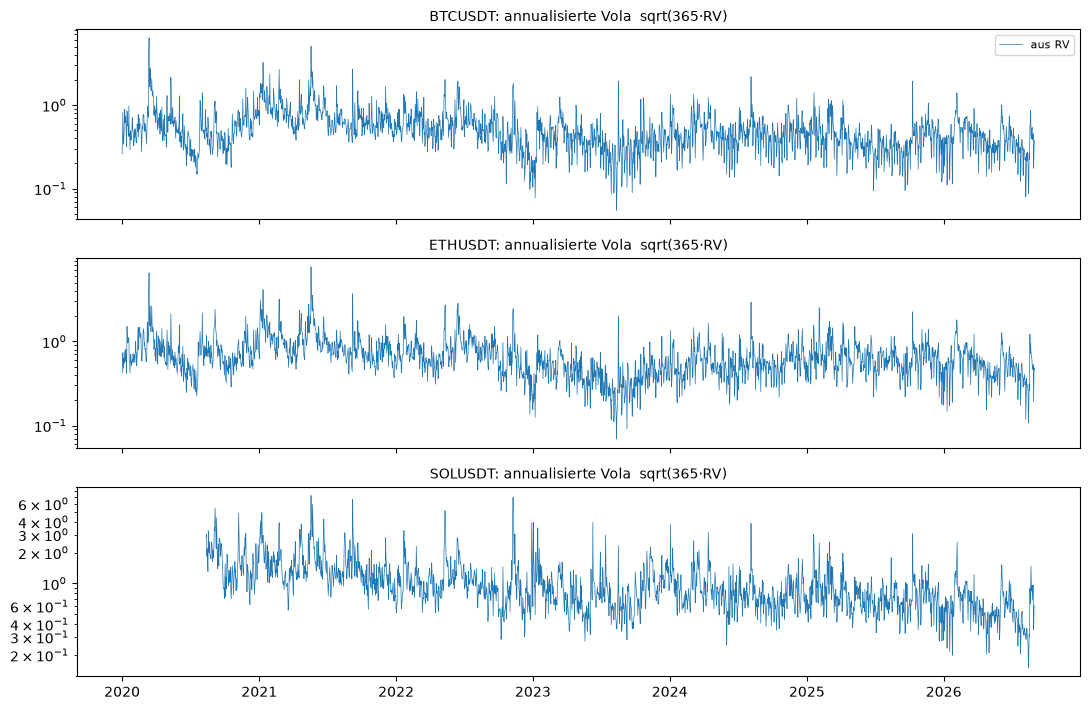

In [6]:
display(pd.DataFrame({sid: {"Start": d.index[0].date(), "Ende": d.index[-1].date(), "Tage": len(d),
                            "ann. Vola (Median)": round(float(np.sqrt(365 * d["rv"]).median()), 3),
                            "Kovariaten": ", ".join(c for c in d.columns if c.startswith("exo_")) or "–"}
                      for sid, d in daily.items()}).T)

fig, axes = plt.subplots(len(daily), 1, figsize=(11, 2.4 * len(daily)), sharex=True, squeeze=False)
for ax, (sid, d) in zip(axes[:, 0], daily.items()):
    ax.plot(np.sqrt(365 * d["rv"]), lw=0.5, label="aus RV")
    if "true_var" in d:
        ax.plot(np.sqrt(365 * d["true_var"]), lw=0.8, label="wahr")
    if "regime" in d and d["regime"].nunique() > 1:     # Regime 1 grau hinterlegen
        ax.fill_between(d.index, 0, 1, where=d["regime"] == d["regime"].max(), color="grey", alpha=0.15,
                        transform=ax.get_xaxis_transform(), label="Regime 1")
    ax.set_yscale("log")
    ax.set_title(f"{sid}: annualisierte Vola  sqrt(365·RV)", fontsize=10)
axes[0, 0].legend(fontsize=8, ncol=3)
plt.tight_layout()
plt.show()